# Computación Avanzada y Analítica

# Solución de ecuaciones no lineales

En este notebook aprenderemos a implementar los principales métodos numéricos para encontrar raíces de funciones no lineales utilizando Python.

## Objetivos

- Comprender el problema de búsqueda de raíces.
- Implementar métodos de intervalo.
- Implementar métodos abiertos.
- Comparar velocidad de convergencia.
- Aplicar los algoritmos a problemas físicos reales.

# Importación de librerías

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. ¿Qué significa encontrar una raíz?

Una raíz de una función es un valor

$$x=\alpha$$

tal que

$$
f(\alpha)=0
$$

Muchos problemas físicos pueden escribirse de esta forma.

Ejemplos:

- Movimiento orbital (Ecuación de Kepler)
- Pozo cuántico finito
- Ecuación de Van der Waals
- Osciladores
- Sistemas eléctricos

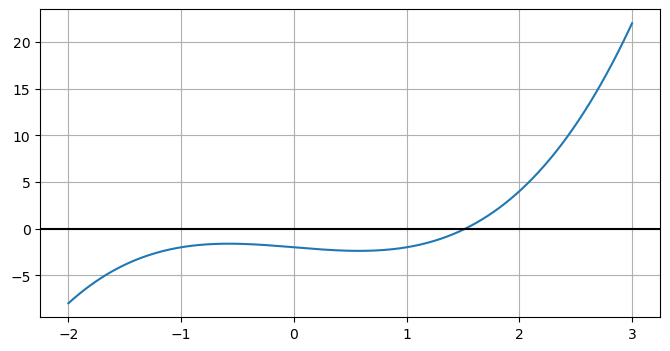

In [2]:
def f(x):
    return x**3 - x - 2

x = np.linspace(-2,3,400)

plt.figure(figsize=(8,4))
plt.plot(x,f(x))
plt.axhline(0,color='k')
plt.grid()
plt.show()

## Encontrando visualmente la raíz

Observe la gráfica.

Preguntas:

- ¿Dónde parece estar la raíz?
- ¿Existe una sola?
- ¿Cómo podría encontrarse con mayor precisión?

# 2. Métodos de intervalo

Los métodos de intervalo utilizan el Teorema del Valor Intermedio.

Si

$$
f(a)f(b)<0
$$

entonces existe al menos una raíz dentro del intervalo.

In [12]:
a=1
b=2

print(f(a))
print(f(b))
print(f(a)*f(b))

-2
4
-8


## Visualización

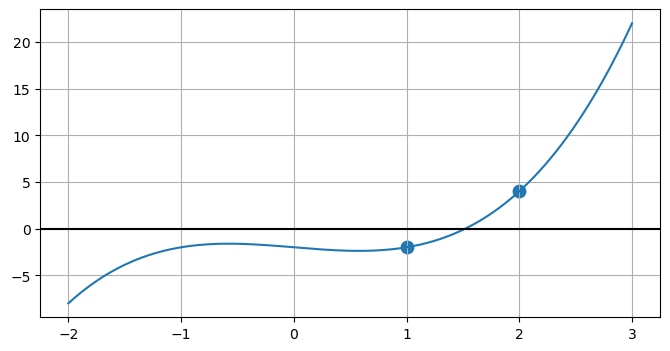

In [13]:
plt.figure(figsize=(8,4))
plt.plot(x,f(x))
plt.scatter([a,b],[f(a),f(b)],s=80)
plt.axhline(0,color='k')
plt.grid()
plt.show()

## 3. Método de Bisección

La idea es muy sencilla.

1. Se calcula el punto medio.

2. Se evalúa la función.

3. Se conserva únicamente el intervalo donde ocurre el cambio de signo.

Este proceso reduce el intervalo a la mitad en cada iteración.

In [14]:
def biseccion(f,a,b,tol=1e-6,max_iter=100):

    historia=[]

    for i in range(max_iter):

        c=(a+b)/2

        historia.append(c)

        if abs(f(c))<tol:
            break

        if f(a)*f(c)<0:
            b=c
        else:
            a=c

    return c,historia

## Ejecución

In [15]:
raiz,h=biseccion(f,1,2)

print(raiz)

1.5213797092437744


## Visualización de la convergencia

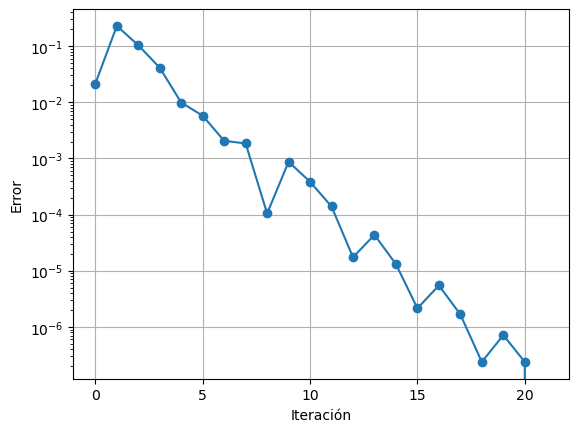

In [16]:
errores=np.abs(np.array(h)-raiz)

plt.semilogy(errores,'o-')
plt.xlabel("Iteración")
plt.ylabel("Error")
plt.grid()
plt.show()

## 4. Método de Falsa Posición

En lugar del punto medio, este método utiliza la intersección de la recta secante con el eje x.

Esto puede acelerar la convergencia dependiendo de la forma de la función.

In [17]:
def falsa_posicion(f,a,b,tol=1e-6,max_iter=100):

    historia=[]

    for i in range(max_iter):

        c=(a*f(b)-b*f(a))/(f(b)-f(a))

        historia.append(c)

        if abs(f(c))<tol:
            break

        if f(a)*f(c)<0:
            b=c
        else:
            a=c

    return c,historia

## Comparación

In [18]:
r,h=falsa_posicion(f,1,2)

print(r)

1.521379636045493


## 5. Métodos abiertos
A diferencia de los métodos anteriores, estos algoritmos no necesitan un intervalo.

Su rapidez suele ser mayor, pero dependen mucho de la condición inicial.

# 6. Newton-Raphson 
El método utiliza la recta tangente

$$
x_{n+1}=x_n-\frac{f(x_n)}{f'(x_n)}
$$

Su convergencia es cuadrática cuando se cumplen las hipótesis matemáticas.

In [19]:
def df(x):
    return 3*x**2-1

In [20]:
def newton(f,df,x0,tol=1e-8,max_iter=50):

    historia=[]

    x=x0

    for i in range(max_iter):

        historia.append(x)

        xn=x-f(x)/df(x)

        if abs(xn-x)<tol:
            return xn,historia

        x=xn

    return x,historia

In [21]:
r,h=newton(f,df,1.5)

print(r)

1.5213797068045676


# 7. Método de la Secante

La secante evita calcular la derivada.

En su lugar aproxima

$$
f'(x)
$$

mediante diferencias finitas.

In [22]:
def secante(f,x0,x1,tol=1e-8,max_iter=50):

    historia=[]

    for i in range(max_iter):

        historia.append(x1)

        x2=x1-f(x1)*(x1-x0)/(f(x1)-f(x0))

        if abs(x2-x1)<tol:
            return x2,historia

        x0=x1
        x1=x2

    return x2,historia

## Comparación entre métodos
Compararemos:

- Número de iteraciones
- Error
- Tiempo

In [23]:
from time import perf_counter
metodos={}

In [25]:
# Bisección
rb, hb = biseccion(f, 1, 2)

# Falsa posición
rf, hf = falsa_posicion(f, 1, 2)

# Newton-Raphson
rn, hn = newton(f, df, 1.5)

# Secante
rs, hs = secante(f, 1, 2)

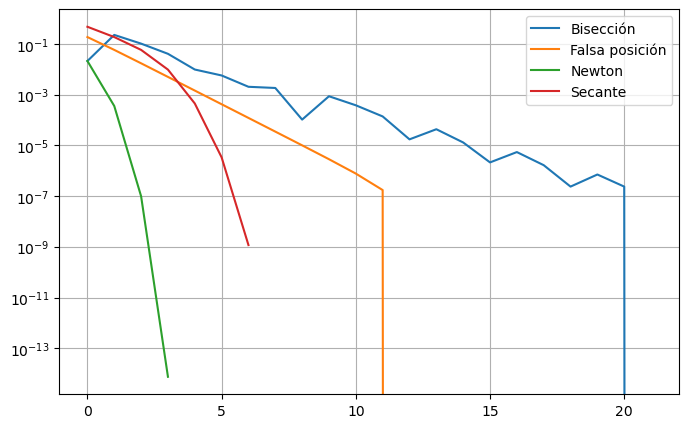

In [26]:
plt.figure(figsize=(8,5))

plt.semilogy(np.abs(np.array(hb)-rb),label="Bisección")
plt.semilogy(np.abs(np.array(hf)-rf),label="Falsa posición")
plt.semilogy(np.abs(np.array(hn)-rn),label="Newton")
plt.semilogy(np.abs(np.array(hs)-rs),label="Secante")

plt.legend()
plt.grid()
plt.show()

# 8. Ejercicios

## Ejercicio 1

Encuentre la raíz de

$$
x^3-4x+1=0
$$

utilizando:

- Bisección
- Newton
- Secante

Compare el número de iteraciones.

---

## Ejercicio 2

Cambie la condición inicial del método de Newton.

¿Qué ocurre cuando la condición inicial está muy lejos de la raíz?

---

## Ejercicio 3

Grafique el error absoluto en escala logarítmica para los cuatro métodos.

¿Puede identificar visualmente cuál converge más rápido?

---

## Ejercicio 4

Implemente un criterio de parada basado en:

$$
|x_{n+1}-x_n|
$$

y compárelo con el criterio

$$
|f(x_n)|.
$$

---

## Ejercicio 5 (Reto)

Utilice `scipy.optimize` (`bisect`, `newton` y `root_scalar`) para resolver el mismo problema y compare el rendimiento con sus implementaciones.